# Figure 3 Supplement 6: Steps just before the decision

Do decisions depend on the last few steps, beyond the pigeon's position? A rule
based on recent steps (e.g. "stop after a big step" or "after two steps the
same way") would make the last steps before a decision larger, toward the
chosen side, than a bound on position does. The stopping model commits when the
position crosses its bound, so its last steps are larger than average only
because crossing selects them; comparing the real steps with the model's,
measured the same way, isolates any extra dependence on recent steps.

For each trial (`pigeon.data.get_steps_before_decision`), signed toward the
chosen side:

- **A — last step:** the step into the decision position,
  `steps[DT] − steps[DT−1]` (the step whose midpoint is the bound estimate).
- **B — step before:** `steps[DT−1] − steps[DT−2]` (DT ≥ 2).

Each panel: per-subject mean at each DT (open black circles, ≥ `MIN_TRIALS`
trials), their median (black line), and the median of the same per-subject
means from data simulated from each subject's stopping-model fit (`SIM_REPS`
repetitions of the subject's real trials, measured with the same pipeline;
dashed blue). Asterisks: paired Wilcoxon signed-rank test, data vs. model,
p < 0.05 after Bonferroni correction over the DTs in the panel.

Columns: OL low-SNR blocks 1–3. Trials: the standard filter
(`get_good_trial_array`) but with DT ≥ 1 (so one-step decisions are included),
finite nonzero bound, raw positions for data and model. Subject-blocks whose
plateau sits at a fit limit are left out (counts printed).

Replaces the old Figure03S02 (`notebooks/archive/Figure03S02_stepSizeBeforeBound.ipynb`),
which compared with a fixed-bound simulation at each subject's median bound.


In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.data import get_good_trial_array, get_steps_before_decision
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import (get_plateau_at_limit, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 20
SIM_SEED = 14
MIN_TRIALS = 5
DTS = np.arange(1, 9)
ALPHA = 0.05
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}
STEPS = [('step_0', 'Last step'), ('step_1', 'Step before')]
KEYS = ['subject_index', 'condition', 'DT']

trials_all = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
trials = trials_all[trials_all.condition.isin(BLOCKS)].copy()
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[(fits.task == 'OL') & fits.group.isin(BLOCKS)]
sim = simulate_stopping_data_table(trials, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
sim = infer_bounds_like_data(sim)

def _subject_means(t):
    lg = get_good_trial_array(t, min_dt=1) & np.isfinite(t.bound) & (t.bound != 0) & t.DT.isin(DTS)
    t = t[lg]
    s = get_steps_before_decision(t, num_steps=2).join(t[KEYS])
    g = s.groupby(KEYS)
    return g.mean().where(g.count() >= MIN_TRIALS), int(lg.sum())

real, n_real = _subject_means(trials)
model, n_sim = _subject_means(sim)
print(f'{n_real} real and {n_sim} simulated trials ({SIM_REPS} repetitions)')
at_limit = fits.loc[get_plateau_at_limit(fits), ['subject_index', 'group']]
l_lim = pd.MultiIndex.from_arrays([real.index.get_level_values(0), real.index.get_level_values(1)]).isin(
    pd.MultiIndex.from_frame(at_limit))
print(f'excluded {at_limit.shape[0]} subject-blocks with the plateau at a fit limit: '
      f'{list(map(tuple, at_limit.to_numpy()))}')
both = real[~l_lim].join(model, rsuffix='_model', how='inner')

rows = []
for b in BLOCKS:
    for col, label in STEPS:
        for dt in DTS:
            try:
                x = both.xs((b, dt), level=['condition', 'DT'])[[col, col + '_model']].dropna()
            except KeyError:
                continue
            if len(x) < 5:
                continue
            rows.append({'block': b, 'step': label, 'DT': dt, 'subjects': len(x), 'data median': x[col].median(),
                         'model median': x[col + '_model'].median(),
                         'median data − model': (x[col] - x[col + '_model']).median(),
                         'p': scipy.stats.wilcoxon(x[col], x[col + '_model']).pvalue})
tests = pd.DataFrame(rows)
tests['p_bonf'] = (tests.p * tests.groupby(['block', 'step']).p.transform('size')).clip(upper=1)
display(tests.round(3))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


10086 real and 208088 simulated trials (20 repetitions)
excluded 5 subject-blocks with the plateau at a fit limit: [(13, 'B3'), (44, 'B3'), (51, 'B1'), (51, 'B2'), (59, 'B1')]


,block,step,DT,subjects,data median,model median,median data − model,p,p_bonf
0,B1,Last step,1,34,0.068,0.053,0.005,0.601,1.000
1,B1,Last step,2,49,0.096,0.102,0.002,0.836,1.000
2,B1,Last step,3,46,0.081,0.080,-0.005,0.837,1.000
3,B1,Last step,4,41,0.081,0.069,0.008,0.538,1.000
4,B1,Last step,5,31,0.102,0.078,0.016,0.399,1.000
5,B1,Last step,6,22,0.053,0.079,-0.009,0.039,0.274
6,B1,Last step,7,7,0.121,0.098,0.006,0.469,1.000
7,B1,Step before,2,49,0.119,0.103,0.018,0.052,0.311
8,B1,Step before,3,46,0.091,0.079,0.018,0.082,0.494
9,B1,Step before,4,41,0.080,0.083,-0.004,0.700,1.000


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


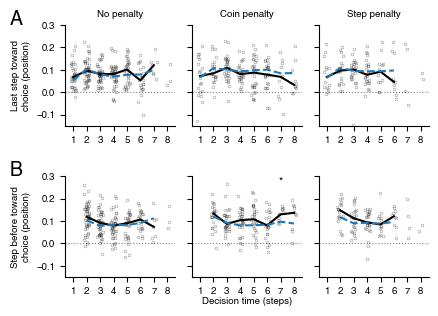

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S06.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'
YLIM = (-0.15, 0.3)

fig = plt.figure(figsize=(11 * CM, 8 * CM))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.15, left=0.14, right=0.98, bottom=0.12, top=0.92)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(2)])
jitter = np.random.default_rng(0)
for c, b in enumerate(BLOCKS):
    g = both.xs(b, level='condition')
    for r, (col, label) in enumerate(STEPS):
        ax = axes[r, c]
        ax.axhline(0, color='0.5', ls=':', lw=0.8)
        d = g[[col, col + '_model']].dropna().reset_index()
        ax.plot(d.DT + jitter.uniform(-0.2, 0.2, len(d)), d[col].clip(*YLIM), 'ko', mfc='none', ms=2, mew=0.4,
                alpha=0.4)
        t = tests[(tests.block == b) & (tests.step == label)]
        ax.plot(t.DT, t['data median'], 'k-', lw=1.5)
        ax.plot(t.DT, t['model median'], '--', color=MODEL, lw=1.5)
        for _, row in t[t.p_bonf < ALPHA].iterrows():
            ax.text(row.DT, YLIM[1] * 0.92, '*', ha='center', va='center', fontsize=8)
        ax.set_xlim(0.4, DTS[-1] + 0.6)
        ax.set_xticks(DTS)
        ax.set_ylim(YLIM)
        ax.set_yticks([-0.1, 0, 0.1, 0.2, 0.3])
        if c > 0:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel(f'{label} toward\nchoice (position)')
        if r == 0:
            ax.set_title(BLOCK_TITLES[b])
        ax.spines[['top', 'right']].set_visible(False)

fig.canvas.draw()
left, right = axes[-1, 0].get_position().x0, axes[-1, -1].get_position().x1
bottom = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in axes[-1])
fig.text((left + right) / 2, bottom - 0.004, 'Decision time (steps)', ha='center', va='top', fontsize=FS)
for r, letter in enumerate('AB'):
    add_panel_label(axes[r, 0], letter, dx=-0.5, dy=1.15)

out = FIGURES_DIR / 'Figure03_S06.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)